# DESI DR2 example: jackknife-calibrated covariance of xi multipoles (LRG, 0.4 < z < 0.6)

This notebook reproduces the DESI DR2 (loa-v1 v1.1) pre-reconstruction covariance for one tracer and redshift bin,
per Galactic cap, and compares it with the official RascalC covariance and with the sample covariance of the
GLAM-Uchuu mocks. It follows the DESI pipeline: the official `pycorr` counts with 60 jackknife regions are the
normalization and jackknife reference, the LSS randoms (one file per cap, cut to the redshift bin) are the sampling
catalog, and NGC and SGC are computed separately and combined afterwards.

The inputs are prepared once with `scripts/desi_dr2_prepare.py` (it needs `pycorr`, `fitsio` and `cosmoprimo`,
i.e. the `cosmodesi` environment) and saved as plain arrays, so that this notebook only needs `numpy` and JAX:

```
source /global/common/software/desi/users/adematti/cosmodesi_environment.sh main
python scripts/desi_dr2_prepare.py LRG NGC 0.4 0.6 <dir_NGC>
python scripts/desi_dr2_prepare.py LRG SGC 0.4 0.6 <dir_SGC>
python scripts/desi_mock_covariance.py "<mock files glob>" <dir>/mock_cov_glam.npz   # GLAM-Uchuu sample covariance
```

In [1]:
import os
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
import numpy as np
import matplotlib.pyplot as plt
import rascaljax as rj
from rascaljax.io_pycorr import load_correlation_input
from rascaljax.postprocess import combine_regions, compare_covariances

base = "/pscratch/sd/w/willlake/rascaljax/"
dirs = {"NGC": base + "desi_dr2_LRG_NGC_z0.4-0.6", "SGC": base + "desi_dr2_LRG_SGC_z0.4-0.6"}
RUN = False  # True: run the integrals here (about an hour on 4 A100s for a converged result); False: load saved results

## Inputs

`CorrelationInput` holds the normalized RR counts in the covariance bins (45 bins of 4 Mpc/h from 20 to 200,
100 mu bins after wrapping), the xi table (100 s bins x 10 mu bins, bin averages that the code refines so that
its interpolant reproduces them) and the jackknife xi and RR counts per region. The randoms carry the
jackknife labels of the same K-means regions (angular, 60 regions, as in `desipipe`).

In [2]:
ci, extra = load_correlation_input(os.path.join(dirs["NGC"], "inputs.npz"))
print("covariance bins", ci.rr.shape, "| xi table", ci.xi_table.xi.shape, "| jackknife", ci.jack_xi.shape)
print("randoms", extra["positions"].shape, "| data galaxies", extra["n_data"])
cat = rj.Catalog(extra["positions"], extra["weights"], n_data=float(extra["n_data"]), jackknife=extra["labels"], name="LRG NGC")

covariance bins (45, 100) | xi table (100, 10) | jackknife (60, 4500)
randoms (3896407, 3) | data galaxies 685959


## Running the integrals

`N2, N3, N4 = 5, 10, 20` are the DESI production settings; `n_loops` sets the total number of sampled quads
(`N_randoms * N2 * N3 * N4 * n_loops`, here 3.9e9 per loop). The example runs in `scripts/desi_dr2_run.py` used 32
loops (6 minutes on 3 A100s, diagonal accurate to a few percent below 100 Mpc/h) and 256 loops for a converged,
positive-definite matrix.

In [3]:
if RUN:
    raw = rj.run_cov([rj.Sample(cat)], {(0, 0): ci}, mode="legendre", max_l=4, N2=5, N3=10, N4=20, n_loops=256, loops_per_sample=16,
                     boxsize=None, xi_cut=250.0, refine_iterations=10, quads_per_batch=5_000_000, seed=42,
                     out_dir=os.path.join(dirs["NGC"], "rascaljax"))
else:
    raw = rj.RawCovariance.load(os.path.join(dirs["NGC"], "rascaljax", "Raw_Covariance.npz"))
print("subsamples", raw.n_sub, "| draws (pairs, triples, quads):", raw.counts["pass0_n_draws"])

subsamples 16 | draws (pairs, triples, quads): [4.98740096e+09 4.98740096e+10 9.97480192e+11]


## Post-processing: shot-noise rescaling from the jackknives

`post_process` builds the jackknife data covariance from the jackknife xi estimates, fits the shot-noise
rescaling $\alpha$ to it with the jackknife-weighted theory terms, assembles the full covariance
$C = C_4 + \alpha C_3 + \alpha^2 C_2$, and returns the bias-corrected precision matrix and $N_{\rm eff}$.
`disconnected=False` matches RascalC's Legendre-projected mode (which omits the jackknife disconnected term).

In [4]:
res = rj.post_process(raw, disconnected=False)
cov = res["full_theory_covariance"]              # (s, ell) ordering
cov_ls = raw.binning.to_pycorr_order(cov)         # (ell, s) ordering, as the official DESI files
print("alpha =", res["shot_noise_rescaling"], " N_eff =", res["N_eff"], " positive definite:", res["positive_definite"])

Fitting the shot-noise rescaling to the jackknife covariance


Jackknife convergence check: min eigenvalue of C2 = 5.74e-09, of C4 = -4.01e-08
Jackknife convergence check: min eigenvalue of C2^-1/2 C4 C2^-1/2 = -0.132 (should be > -1.00)


Shot-noise rescaling(s): [0.98486328]
Full convergence check: min eigenvalue of C2 = 8.45e-09, of C4 = -4.82e-08
Full convergence check: min eigenvalue of C2^-1/2 C4 C2^-1/2 = -0.147 (should be > -0.97)
Effective number of samples N_eff = 7.6095e+04
Extra convergence check on the full covariance:
First half vs second half: R_inv = 1.26e-01, 1.24e-01; D_KL = 5.16e-01, 5.11e-01; chi2_red-1 = 8.84e-03, 6.37e-03
Even vs odd subsamples: R_inv = 1.21e-01, 1.20e-01; D_KL = 4.80e-01, 4.76e-01; chi2_red-1 = 8.34e-03, 5.82e-03
alpha = [0.98486328]  N_eff = 76094.94099224538  positive definite: True


## Comparison with the official RascalC covariance and the GLAM-Uchuu mocks

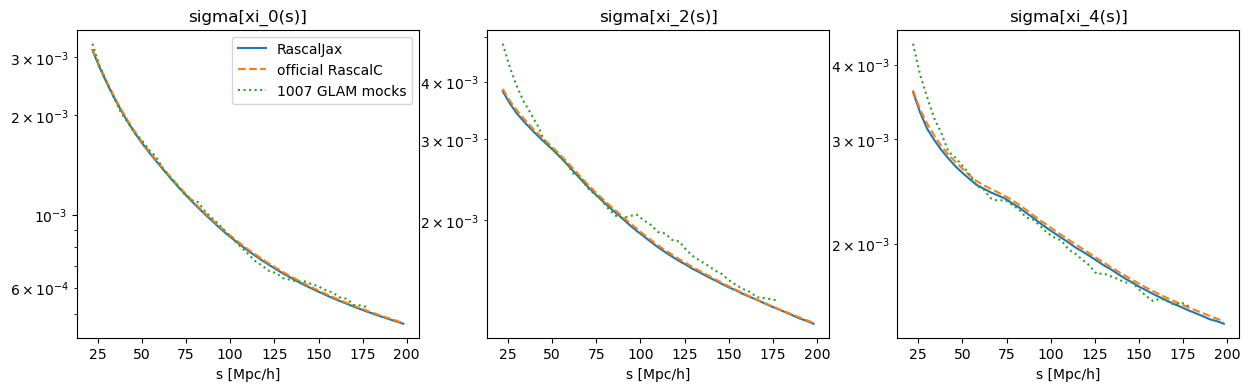

In [5]:
n_s, n_ell = raw.binning.n_s, raw.binning.n_ell
s_mid = raw.binning.s_mid
off = extra["rascalc_cov"]                       # official, (ell, s) ordering, ells 0, 2, 4
m = np.load(os.path.join(dirs["NGC"], "mock_cov_glam.npz")); mock = m["cov_ell_s"]; n_sm = len(mock) // n_ell
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for l in range(3):
    sl = slice(l * n_s, (l + 1) * n_s)
    ax[l].plot(s_mid, np.sqrt(np.diag(cov_ls)[sl]), label="RascalJax")
    ax[l].plot(s_mid, np.sqrt(np.diag(off)[sl]), "--", label="official RascalC")
    ax[l].plot(s_mid[:n_sm], np.sqrt(np.diag(mock)[l * n_sm:(l + 1) * n_sm]), ":", label=f"{int(m['n_mocks'])} GLAM mocks")
    ax[l].set_yscale("log"); ax[l].set_title(f"sigma[xi_{2*l}(s)]"); ax[l].set_xlabel("s [Mpc/h]")
ax[0].legend();

In [6]:
keep = np.concatenate([l * n_s + np.arange(n_sm) for l in range(n_ell)])  # the mocks stop at s = 180
compare_covariances(off, cov_ls, label="official (inverted) vs RascalJax: ")
compare_covariances(cov_ls[keep[:, None], keep[None, :]], mock, label="RascalJax (inverted) vs mocks: ")
compare_covariances(off[keep[:, None], keep[None, :]], mock, label="official (inverted) vs mocks: ");

official (inverted) vs RascalJax: R_inv = 7.17e-02, 7.00e-02; D_KL = 1.70e-01, 1.67e-01; chi2_red-1 = -6.26e-03, 1.12e-02
RascalJax (inverted) vs mocks: R_inv = 3.57e-01, 4.99e-01; D_KL = 4.19e+00, 5.29e+00; chi2_red-1 = -3.62e-02, 1.94e-01
official (inverted) vs mocks: R_inv = 3.51e-01, 5.01e-01; D_KL = 4.13e+00, 5.28e+00; chi2_red-1 = -4.53e-02, 2.02e-01


## Combining NGC and SGC

The GCcomb correlation function is the RR-weighted average of the caps' (s, mu)-binned estimators; the covariance
follows by propagating the derivatives through the Legendre projection (Appendix B.2 of Rashkovetskyi et al.
2025), neglecting correlations between the caps. The weights are the unnormalized RR counts of each cap.

NGC alpha = [0.98486328]
SGC alpha = [1.01318359]


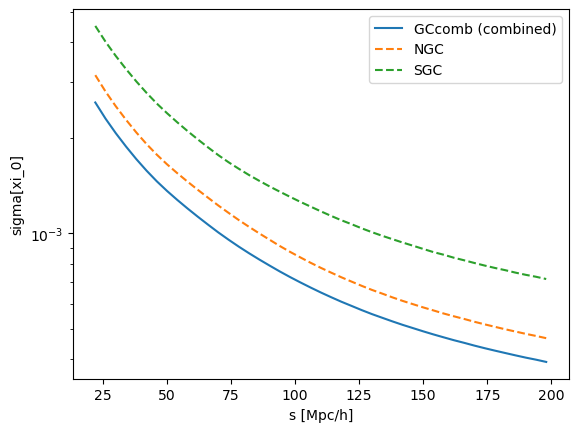

In [7]:
covs, weights = [], []
inputs = {cap: np.load(os.path.join(d, "inputs.npz")) for cap, d in dirs.items()}
have_wcounts = all("rr_wcounts" in inp.files for inp in inputs.values())  # one weight convention for both caps
for cap, d in dirs.items():
    r = np.load(os.path.join(d, "rascaljax", "Rescaled_Covariance.npz"))
    inp = inputs[cap]
    covs.append(r["full_theory_covariance"])
    # unnormalized RR counts as weights (or normalized counts x (sum of random weights)^2 if not stored)
    weights.append(inp["rr_wcounts"].ravel() if have_wcounts else inp["rr"].ravel() * inp["weights"].sum() ** 2)
    print(cap, "alpha =", r["shot_noise_rescaling"])
cov_comb = combine_regions(covs, weights, raw.binning)
cov_comb_ls = raw.binning.to_pycorr_order(cov_comb)
plt.plot(s_mid, np.sqrt(np.diag(cov_comb_ls)[:n_s]), label="GCcomb (combined)")
for cap, c in zip(dirs, covs):
    plt.plot(s_mid, np.sqrt(np.diag(raw.binning.to_pycorr_order(c))[:n_s]), "--", label=cap)
plt.yscale("log"); plt.xlabel("s [Mpc/h]"); plt.ylabel("sigma[xi_0]"); plt.legend();

The combined matrix can be exported in the DESI (ell, s) ordering with `np.savetxt`, or handed to
`desilike`/`desi-clustering` the way the official RascalC text covariances are.